# Project 2 – Model comparison: Neural network vs Logistic regression (McNemar)

The model code below is copied **cell by cell, word for word** from
`Project2_LogReg_clean.ipynb` and `Project2_NN_clean.ipynb`. Nothing is changed.
Cells that only make plots (and do not change any variables) are left out.

Put this notebook in the same folder as `diabetes_012_health_indicators_BRFSS2015.csv` and run all cells.

**Check before using the result:** the test accuracies printed in section 1 and 2 must be the same as in the
two original notebooks (LogReg 0.731, NN 0.714). If the NN number is different, the network has trained slightly
differently on this computer, and the McNemar result belongs to *this* run.

## 1. Logistic regression (cells copied from `Project2_LogReg_clean.ipynb`)

In [1]:
import numpy as np
import pandas as pd
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (log_loss, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, average_precision_score,
                             balanced_accuracy_score)
from sklearn.exceptions import ConvergenceWarning
import matplotlib.pyplot as plt
import seaborn as sns

# we deliberately run 1 iteration per call, so sklearn will warn every time - hide that
warnings.filterwarnings("ignore", category=ConvergenceWarning)

MODEL_TAG = 'LogReg'   # used in plot titles and file names

In [2]:
# split
test_size = 0.20          # 80/20 train/test
val_size = 0.20           # fraction of the TRAINING data used for validation (early stopping)
seed = 42
SEED = seed

# training
max_epochs = 100
C_reg = 1.0               # inverse regularization strength (smaller = stronger regularization)

# early stopping
patience = 5              # epochs without improvement before stopping
min_delta = 1e-5          # minimum decrease in val loss to count as an improvement

In [3]:
# Load data
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset shape:", df.shape)
print("\nOriginal 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):")
print(df["Diabetes_012"].value_counts().sort_index())
df.head()

Dataset shape: (253680, 22)

Original 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [4]:
# The task: does the person have prediabetes OR diabetes?  (Diabetes_012 = 1 or 2  ->  1)
df["Diabetes_binary"] = (df["Diabetes_012"] > 0).astype(int)

TARGET = "Diabetes_binary"
feature_names = [c for c in df.columns if c not in ["Diabetes_012", TARGET]]
FEATURE_COLS = feature_names
class_names = ['No diabetes', 'Prediabetes/Diabetes']
pos_label = 1          # index of the positive class

X = df[feature_names].values
y = df[TARGET].values.astype(int)
y012 = df["Diabetes_012"].values.astype(int)   # only used to colour the latent-space plots

print(f"X: {X.shape}, y: {y.shape}")
print(f"Classes (binary): {np.bincount(y)}")

X: (253680, 21), y: (253680,)
Classes (binary): [213703  39977]


In [5]:
# 80/20 split
X_train_raw, X_test_raw, y_train, y_test, y012_train, y012_test = train_test_split(
    X, y, y012, test_size=test_size, random_state=seed, stratify=y)

# validation set taken from the training data
X_train_raw, X_val_raw, y_train, y_val, y012_train, y012_val = train_test_split(
    X_train_raw, y_train, y012_train, test_size=val_size, random_state=seed, stratify=y_train)

print(f"Train: {X_train_raw.shape[0]}, Val: {X_val_raw.shape[0]}, Test: {X_test_raw.shape[0]}")
print(f"Share of positives  train: {y_train.mean():.3f}   val: {y_val.mean():.3f}   test: {y_test.mean():.3f}")

Train: 162355, Val: 40589, Test: 50736
Share of positives  train: 0.158   val: 0.158   test: 0.158


In [6]:
train_mean = np.mean(X_train_raw, axis=0)
train_std = np.std(X_train_raw, axis=0)

X_train = (X_train_raw - train_mean) / train_std
X_val = (X_val_raw - train_mean) / train_std
X_test = (X_test_raw - train_mean) / train_std

print("Train mean:", np.round(np.mean(X_train, axis=0), 3))
print("Train std: ", np.round(np.std(X_train, axis=0), 3))

Train mean: [-0.  0. -0. -0.  0. -0. -0.  0. -0.  0. -0. -0. -0.  0. -0.  0.  0.  0.
  0.  0. -0.]
Train std:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [7]:
n_train = len(y_train)
n_neg = int(np.sum(y_train == 0))
n_pos = int(np.sum(y_train == 1))

w_neg = n_train / (2 * n_neg)
w_pos = n_train / (2 * n_pos)
class_weights = {0: w_neg, 1: w_pos}

# one weight per example (used for the weighted log loss)
sw_train = np.where(y_train == 1, w_pos, w_neg)
sw_val = np.where(y_val == 1, w_pos, w_neg)
sw_test = np.where(y_test == 1, w_pos, w_neg)

print(f'Negatives in train: {n_neg}  -> weight {w_neg:.3f}')
print(f'Positives in train: {n_pos}  -> weight {w_pos:.3f}')
print(f'Ratio w_pos / w_neg = {w_pos / w_neg:.3f}')

Negatives in train: 136769  -> weight 0.594
Positives in train: 25586  -> weight 3.173
Ratio w_pos / w_neg = 5.345


In [8]:
model = LogisticRegression(solver='lbfgs', max_iter=1, warm_start=True,
                           C=C_reg, class_weight=class_weights, random_state=seed)

train_losses = []
val_losses = []

best_val_loss = np.inf
best_coef = None
best_intercept = None
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(max_epochs):
    # one epoch of training
    model.fit(X_train, y_train)

    # weighted loss on train and validation
    train_loss = log_loss(y_train, model.predict_proba(X_train), sample_weight=sw_train)
    val_loss = log_loss(y_val, model.predict_proba(X_val), sample_weight=sw_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # early stopping check
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_coef = model.coef_.copy()
        best_intercept = model.intercept_.copy()
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement = epochs_without_improvement + 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

# restore the best weights
model.coef_ = best_coef
model.intercept_ = best_intercept

print(f"Best epoch: {best_epoch}, val loss: {best_val_loss:.4f}")

Early stopping at epoch 16
Best epoch: 11, val loss: 0.5182


In [9]:
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)
test_pred = model.predict(X_test)

train_acc = np.mean(train_pred == y_train)
val_acc = np.mean(val_pred == y_val)
test_acc = np.mean(test_pred == y_test)

print(f"Train accuracy: {train_acc:.3f}")
print(f"Val accuracy:   {val_acc:.3f}")
print(f"Test accuracy:  {test_acc:.3f}")

Train accuracy: 0.729
Val accuracy:   0.730
Test accuracy:  0.731


In [10]:
# Save the LogReg test predictions before the NN code overwrites the variable names
pred_lr = np.array(test_pred).astype(int).copy()
y_test_lr = np.array(y_test).astype(int).copy()
acc_lr_notebook = test_acc
print(f"LogReg test accuracy: {acc_lr_notebook:.4f}")

LogReg test accuracy: 0.7306


## 2. Neural network (cells copied from `Project2_NN_clean.ipynb`)

In [11]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_TAG = 'NN'   # used in plot titles and file names

In [12]:
# Loads the dataset
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\nOriginal 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):")
print(df["Diabetes_012"].value_counts().sort_index())

Dataset shape: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0



Original 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


In [13]:
# The task: does the person have prediabetes OR diabetes?  (Diabetes_012 = 1 or 2  ->  1)
df["Diabetes_binary"] = (df["Diabetes_012"] > 0).astype(float)

TARGET = "Diabetes_binary"
FEATURE_COLS = [c for c in df.columns if c not in ["Diabetes_012", TARGET]]
feature_names = FEATURE_COLS
class_names = ['No diabetes', 'Prediabetes/Diabetes']
pos_label = 1   # index of the positive class

print("Number of features:", len(FEATURE_COLS))
print("\nBinary target distribution:")
print(df[TARGET].value_counts().sort_index())

Number of features: 21

Binary target distribution:
Diabetes_binary
0.0    213703
1.0     39977
Name: count, dtype: int64


In [14]:
# Separate features and target
X = df[FEATURE_COLS].to_numpy(dtype=np.float32)
y = df[TARGET].to_numpy(dtype=np.float32)
y012 = df["Diabetes_012"].to_numpy(dtype=int)   # only used to colour the latent-space plots

# Keep 20% completely separate for final testing
X_train_raw, X_test_raw, y_train, y_test, y012_train, y012_test = train_test_split(
    X, y, y012,
    test_size=0.20,
    random_state=SEED,
    stratify=y   # keeps approximately the same proportion of classes in both sets
)

# Make a validation set from the remaining data
X_train_raw, X_val_raw, y_train, y_val, y012_train, y012_val = train_test_split(
    X_train_raw, y_train, y012_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

print(f'Train: {X_train_raw.shape}, Validation: {X_val_raw.shape}, Test: {X_test_raw.shape}')
print(f'Share of positives  train: {y_train.mean():.3f}   val: {y_val.mean():.3f}   test: {y_test.mean():.3f}')

Train: (162355, 21), Validation: (40589, 21), Test: (50736, 21)
Share of positives  train: 0.158   val: 0.158   test: 0.158


In [15]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (162355, 21)
Validation: (40589, 21)
Test: (50736, 21)


In [16]:
n_neg = int(np.sum(y_train == 0))
n_pos = int(np.sum(y_train == 1))
pos_weight = n_neg / n_pos

print(f'Negatives in train: {n_neg}')
print(f'Positives in train: {n_pos}')
print(f'pos_weight = {n_neg} / {n_pos} = {pos_weight:.3f}')

Negatives in train: 136769
Positives in train: 25586
pos_weight = 136769 / 25586 = 5.345


In [17]:
# Convert data to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

batch_size = 256

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=batch_size,
    shuffle=False
)

In [18]:
# This is our neural network (small and simple)

class DiabetesNN(nn.Module):
    def __init__(self, n_features):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(n_features, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


model = DiabetesNN(n_features=X_train.shape[1])

# BCEWithLogitsLoss already includes the sigmoid operation internally (BCE = Binary Cross Entropy)
# pos_weight gives the positive class more weight in the loss (class imbalance)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [19]:
# Train the model with simple early stopping

max_epochs = 100   # 1 epoch = the network has seen every training observation once
patience = 5       # if validation loss doesn't improve for 5 epochs in a row, stop training

best_val_loss = float("inf")
epochs_without_improvement = 0
best_model_state = None

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(max_epochs):

    # ----- Training -----
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

        predictions = (torch.sigmoid(logits) >= 0.5).float()
        correct += (predictions == y_batch).sum().item()
        total += y_batch.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # ----- Validation -----
    model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

            predictions = (torch.sigmoid(logits) >= 0.5).float()
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

    val_loss = running_val_loss / total
    val_accuracy = correct / total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.3f} | "
        f"val acc: {val_accuracy:.3f}"
    )

    # ----- Early stopping -----
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

# Use the weights from the epoch with the lowest validation loss
model.load_state_dict(best_model_state)

Epoch 01 | train loss: 0.8992 | val loss: 0.8643 | train acc: 0.716 | val acc: 0.697
Epoch 02 | train loss: 0.8649 | val loss: 0.8595 | train acc: 0.713 | val acc: 0.709
Epoch 03 | train loss: 0.8617 | val loss: 0.8579 | train acc: 0.715 | val acc: 0.706
Epoch 04 | train loss: 0.8601 | val loss: 0.8588 | train acc: 0.714 | val acc: 0.703
Epoch 05 | train loss: 0.8592 | val loss: 0.8581 | train acc: 0.715 | val acc: 0.725
Epoch 06 | train loss: 0.8584 | val loss: 0.8589 | train acc: 0.716 | val acc: 0.733
Epoch 07 | train loss: 0.8576 | val loss: 0.8572 | train acc: 0.717 | val acc: 0.716
Epoch 08 | train loss: 0.8567 | val loss: 0.8572 | train acc: 0.717 | val acc: 0.721
Epoch 09 | train loss: 0.8565 | val loss: 0.8584 | train acc: 0.717 | val acc: 0.725
Epoch 10 | train loss: 0.8557 | val loss: 0.8576 | train acc: 0.719 | val acc: 0.724
Epoch 11 | train loss: 0.8557 | val loss: 0.8582 | train acc: 0.719 | val acc: 0.705
Epoch 12 | train loss: 0.8551 | val loss: 0.8574 | train acc: 0.7

<All keys matched successfully>

Test accuracy:          0.714
Test balanced accuracy: 0.746
ROC-AUC:                0.824
PR-AUC (avg precision): 0.460   (random model = 0.158)

Classification report:
                      precision    recall  f1-score   support

         No diabetes      0.947     0.699     0.805     42741
Prediabetes/Diabetes      0.330     0.792     0.466      7995

            accuracy                          0.714     50736
           macro avg      0.639     0.746     0.635     50736
        weighted avg      0.850     0.714     0.751     50736



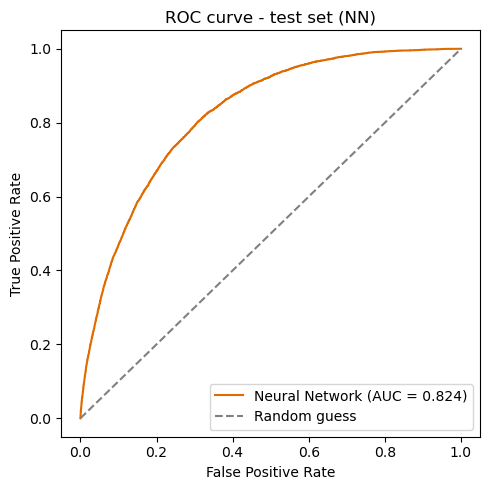

In [20]:
# Evaluation once on the untouched test set
model.eval()

with torch.no_grad():
    test_logits = model(X_test_t)
    test_probabilities = torch.sigmoid(test_logits).cpu().numpy().ravel()

test_predictions = (test_probabilities >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test, test_predictions)
test_bal_acc = balanced_accuracy_score(y_test, test_predictions)
test_auc = roc_auc_score(y_test, test_probabilities)
test_ap = average_precision_score(y_test, test_probabilities)

print(f"Test accuracy:          {test_accuracy:.3f}")
print(f"Test balanced accuracy: {test_bal_acc:.3f}")
print(f"ROC-AUC:                {test_auc:.3f}")
print(f"PR-AUC (avg precision): {test_ap:.3f}   (random model = {y_test.mean():.3f})")

print("\nClassification report:")
print(classification_report(y_test, test_predictions, target_names=class_names, digits=3))

fpr_nn, tpr_nn, _ = roc_curve(y_test, test_probabilities)

plt.figure(figsize=(5, 5))
plt.plot(fpr_nn, tpr_nn, label=f'Neural Network (AUC = {test_auc:.3f})', color='#e06c00')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve - test set (NN)')
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# Save the NN test predictions
pred_nn = np.array(test_predictions).astype(int).copy()
y_test_nn = np.array(y_test).astype(int).copy()
acc_nn_notebook = test_accuracy
print(f"NN test accuracy: {acc_nn_notebook:.4f}")

NN test accuracy: 0.7140


## 3. McNemar test

### 3.1 Check: same test set?
McNemar is a **paired** test, so both models must be evaluated on the same persons in the same order.

In [22]:
print("Same number of test persons:", len(y_test_lr) == len(y_test_nn))
print("Same labels in same order:  ", np.all(y_test_lr == y_test_nn))

y_true = y_test_lr
n = len(y_true)
print("n =", n)

Same number of test persons: True
Same labels in same order:   True
n = 50736


### 3.2 The 2×2 table
For every test person we check whether each model was right or wrong (model A = NN, model B = LR):

|                | LR correct | LR wrong |
|----------------|-----------|----------|
| **NN correct** | $n_{11}$ | $n_{12}$ |
| **NN wrong**   | $n_{21}$ | $n_{22}$ |

Only the two "disagreement" cells $n_{12}$ and $n_{21}$ matter for the test.

In [23]:
correct_nn = (pred_nn == y_true)     # True if NN was right for this person
correct_lr = (pred_lr == y_true)     # True if LogReg was right for this person

n11 = int(np.sum(correct_nn & correct_lr))      # both right
n12 = int(np.sum(correct_nn & ~correct_lr))     # only NN right
n21 = int(np.sum(~correct_nn & correct_lr))     # only LR right
n22 = int(np.sum(~correct_nn & ~correct_lr))    # both wrong

table = pd.DataFrame([[n11, n12], [n21, n22]],
                     index=['NN correct', 'NN wrong'],
                     columns=['LR correct', 'LR wrong'])
print(table)
print()
print("Check: n11 + n12 + n21 + n22 =", n11 + n12 + n21 + n22, " (should be", n, ")")

acc_nn = (n11 + n12) / n
acc_lr = (n11 + n21) / n
print(f"\nAccuracy NN: {acc_nn:.4f}   (from section 2: {acc_nn_notebook:.4f})")
print(f"Accuracy LR: {acc_lr:.4f}   (from section 1: {acc_lr_notebook:.4f})")

            LR correct  LR wrong
NN correct       35012      1216
NN wrong          2057     12451

Check: n11 + n12 + n21 + n22 = 50736  (should be 50736 )

Accuracy NN: 0.7140   (from section 2: 0.7140)
Accuracy LR: 0.7306   (from section 1: 0.7306)


### 3.3 Test statistic, confidence interval and p-value

$H_0$: the two models have the same accuracy, $\theta = \theta_{NN} - \theta_{LR} = 0$.

Estimated difference in accuracy:
$$\hat\theta = \frac{n_{12} - n_{21}}{n}$$

Confidence interval (Beta approximation):
$$Q = \frac{n^2 (n+1)(\hat\theta+1)(1-\hat\theta)}{n(n_{12}+n_{21}) - (n_{12}-n_{21})^2}, \quad
f = \frac{\hat\theta+1}{2}(Q-1), \quad g = \frac{1-\hat\theta}{2}(Q-1)$$
$$\theta_L = 2\,\text{Beta}^{-1}(\tfrac{\alpha}{2}; f, g) - 1, \qquad
\theta_U = 2\,\text{Beta}^{-1}(1-\tfrac{\alpha}{2}; f, g) - 1$$

p-value (exact, under $H_0$ the disagreements are a fair coin):
$$p = 2\,\text{cdf}_{\text{Binom}}\big(\min(n_{12}, n_{21});\ n_{12}+n_{21},\ \tfrac12\big)$$

In [24]:
from scipy import stats

alpha = 0.05

# estimated difference in accuracy (NN - LR)
theta_hat = (n12 - n21) / n

# confidence interval
Q = (n**2 * (n + 1) * (theta_hat + 1) * (1 - theta_hat)) / (n * (n12 + n21) - (n12 - n21)**2)
f = (theta_hat + 1) / 2 * (Q - 1)
g = (1 - theta_hat) / 2 * (Q - 1)

theta_L = 2 * stats.beta.ppf(alpha / 2, f, g) - 1
theta_U = 2 * stats.beta.ppf(1 - alpha / 2, f, g) - 1

# p-value (exact binomial)
m = n12 + n21
p_value = 2 * stats.binom.cdf(min(n12, n21), m, 0.5)
p_value = min(p_value, 1.0)

print(f"theta_hat = acc_NN - acc_LR = {theta_hat:.4f}")
print(f"{int((1 - alpha) * 100)}% CI for theta:      [{theta_L:.4f}, {theta_U:.4f}]")
print(f"p-value:                    {p_value:.3g}")

theta_hat = acc_NN - acc_LR = -0.0166
95% CI for theta:      [-0.0188, -0.0144]
p-value:                    2.47e-49


### 3.4 Plot
$\frac{\theta+1}{2}$ follows (approximately) a Beta($f$, $g$) distribution. To draw the density of $\theta$ itself
we change variable: $p_\theta(x) = \frac{1}{2}\,\text{Beta-pdf}\!\left(\frac{x+1}{2}; f, g\right)$.

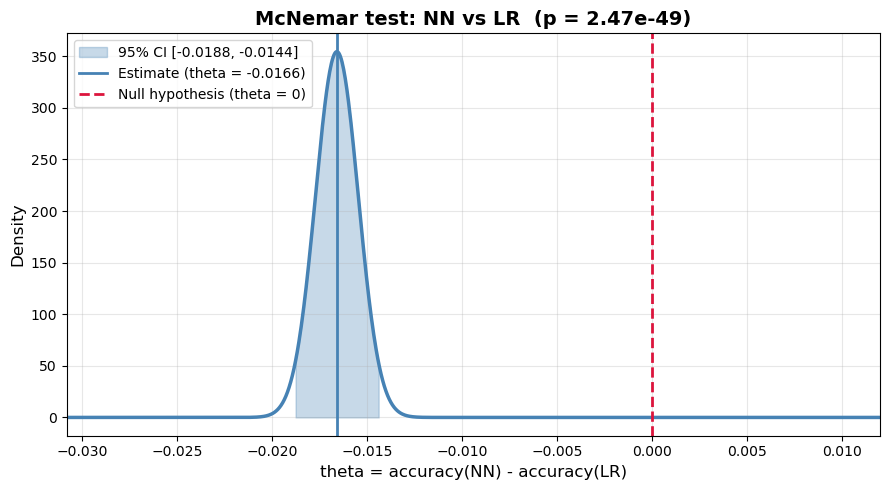

In [25]:
# x-axis range: include both 0 and the whole confidence interval
x_min = min(0, theta_L) - 0.012
x_max = max(0, theta_U) + 0.012
x = np.linspace(x_min, x_max, 1000)

# density of theta (change of variable from the Beta distribution)
density = stats.beta.pdf((x + 1) / 2, f, g) / 2

# the part of the curve inside the confidence interval
in_ci = (x >= theta_L) & (x <= theta_U)

plt.figure(figsize=(9, 5))
plt.fill_between(x[in_ci], density[in_ci], color='steelblue', alpha=0.3,
                 label=f'95% CI [{theta_L:.4f}, {theta_U:.4f}]')
plt.plot(x, density, color='steelblue', linewidth=2.5)
plt.axvline(theta_hat, color='steelblue', linewidth=2,
            label=f'Estimate (theta = {theta_hat:.4f})')
plt.axvline(0, color='crimson', linestyle='--', linewidth=2,
            label='Null hypothesis (theta = 0)')
plt.xlim(x_min, x_max)
plt.xlabel('theta = accuracy(NN) - accuracy(LR)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.title(f'McNemar test: NN vs LR  (p = {p_value:.3g})', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.5 Cross-check: classic chi² version
$$\chi^2 = \frac{(|n_{12} - n_{21}| - 1)^2}{n_{12} + n_{21}}$$
With this many test persons the two p-values should be very close.

In [26]:
chi2_stat = (abs(n12 - n21) - 1)**2 / (n12 + n21)
p_chi2 = 1 - stats.chi2.cdf(chi2_stat, df=1)

print(f"chi2 = {chi2_stat:.3f}")
print(f"p-value (chi2):           {p_chi2:.3g}")
print(f"p-value (exact binomial): {p_value:.3g}")

chi2 = 215.582
p-value (chi2):           0
p-value (exact binomial): 2.47e-49


### 3.6 Interpretation (for you to write)
1. Which side of 0 is $\hat\theta$ on, and which model does that favour?
2. Does the 95% confidence interval contain 0? Can you reject $H_0$ at $\alpha = 0.05$?
3. How big is $\hat\theta$ in percentage points, and does that matter in practice?
4. Both models were trained with class weights. Is accuracy the best metric to compare them on with this imbalanced data?